Import the necessary modules. We need stationarity from ntrfc and some other modules for the definition of a signal and for rendering a plot

In [18]:
from ntrfc.timeseries.stationarity import estimate_stationarity
import numpy as np
import matplotlib.pyplot as plt

In [19]:

def signal_generator(amplitude=1, frequency=1, mean=0, abate=None, noise_amplitude=0.0, time=10.0, resolution=128):
    step = time * (frequency * resolution)
    times = np.linspace(0, time, step)
    noise = np.random.normal(-1, 1, len(times)) * noise_amplitude if noise_amplitude else 0
    decay = np.e ** -(times * abate) if abate else 0
    values = amplitude * np.sin(frequency * times* (np.pi*2)) + mean + decay + noise
    return times, values

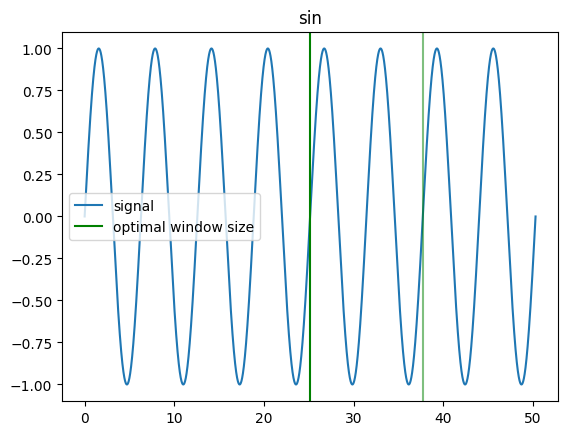

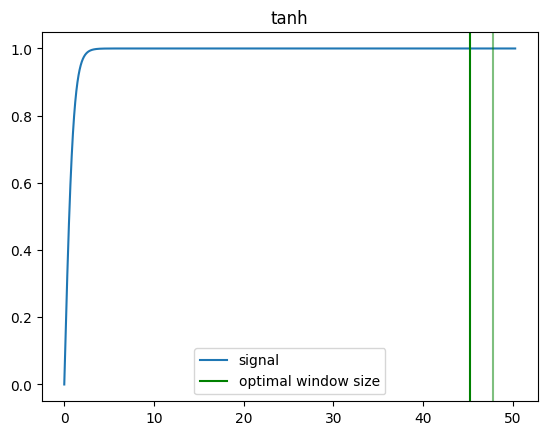

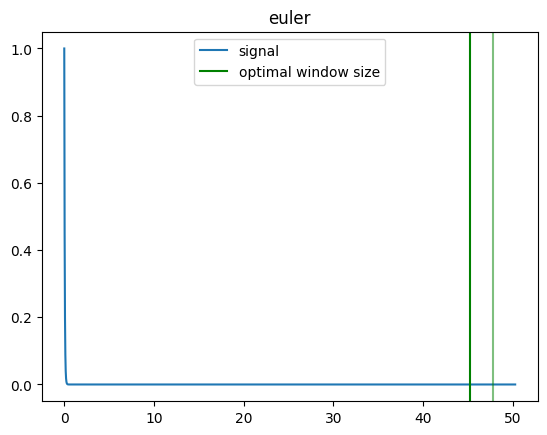

In [20]:
from ntrfc.timeseries.stationarity import optimal_window_size
# sine
res = 10000

nper = 8
x = np.linspace(0, 2 * np.pi * nper, res)

# sin
# we have four periods, at least one period should be captured
# thats res // 4 as a return
ysin = np.sin(x)
opt_window, opt_window_size, _ = optimal_window_size(ysin)

f,axs = plt.subplots(1,1)
axs.plot(x, ysin, label="signal")
axs.axvline(x=x[-2*opt_window_size],ymin=-1,ymax=1, color="green", label="optimal window size")
axs.axvline(x=x[-opt_window_size],ymin=-1,ymax=1, color="green",alpha=0.5)
axs.set_title("sin")
axs.legend()
plt.show()

# tanh
tanh = np.tanh(x * 1)
opt_window, opt_window_size, _ = optimal_window_size(tanh)

f,axs = plt.subplots(1,1)
axs.plot(x, tanh, label="signal")
axs.axvline(x=x[-2*opt_window_size],ymin=-1,ymax=1, color="green", label="optimal window size")
axs.axvline(x=x[-opt_window_size],ymin=-1,ymax=1, color="green",alpha=0.5)
axs.set_title("tanh")
axs.legend()
plt.show()
# euler
eul = np.e ** (-x * 20)
opt_window, opt_window_size, _ = optimal_window_size(eul)

f,axs = plt.subplots(1,1)
axs.plot(x, eul, label="signal")
axs.axvline(x=x[-2*opt_window_size],ymin=-1,ymax=1, color="green", label="optimal window size")
axs.axvline(x=x[-opt_window_size],ymin=-1,ymax=1, color="green", alpha=0.5)
axs.set_title("euler")
axs.legend()
plt.show()


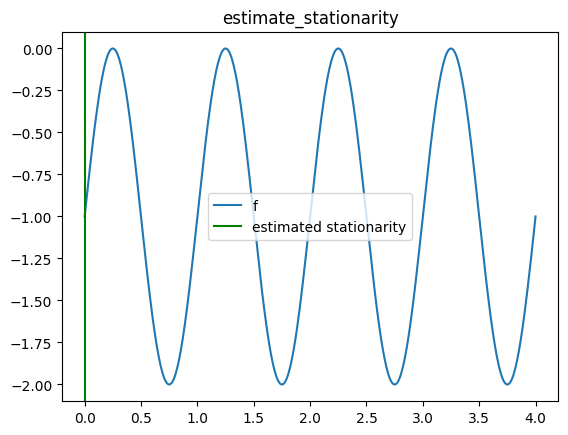

In [21]:
amplitude = 1 # 1,10
frequency = 1  # 1,10
time = 4  # 10, 60
mean = -1  # -1,0,1

timesteps, values = signal_generator(amplitude=amplitude, frequency=frequency, mean=mean, time=time)
stationary_timestep = estimate_stationarity(values)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values, label="f")
axs.axvline(x=timesteps[stationary_timestep],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.set_title("estimate_stationarity")
axs.legend()
plt.show()

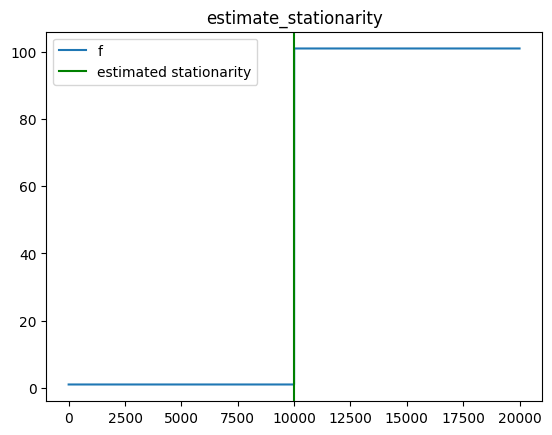

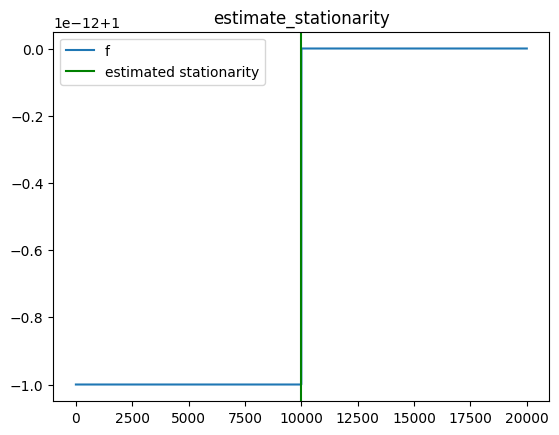

In [22]:
res = 20000

snr_false = 1e2
signal_amplitude = 1
values_stationary = signal_amplitude * np.ones(res)
stepsize = snr_false / signal_amplitude
values_stationary[res//2:] = 1 + stepsize
stationary_timestep_false = estimate_stationarity(values_stationary)
timesteps = np.arange(0,res)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values_stationary, label="f")
axs.axvline(x=timesteps[stationary_timestep_false],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.set_title("estimate_stationarity")
axs.legend()
plt.show()

snr = 1e-12
stepsize = snr / signal_amplitude
values_stationary = np.ones(res) * signal_amplitude
values_stationary[res // 2:] = 1 + stepsize
stationary_timestep_true = estimate_stationarity(values_stationary)


f,axs = plt.subplots(1,1)
axs.plot(timesteps, values_stationary, label="f")
axs.set_title("estimate_stationarity")
axs.axvline(x=timesteps[stationary_timestep_false],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()

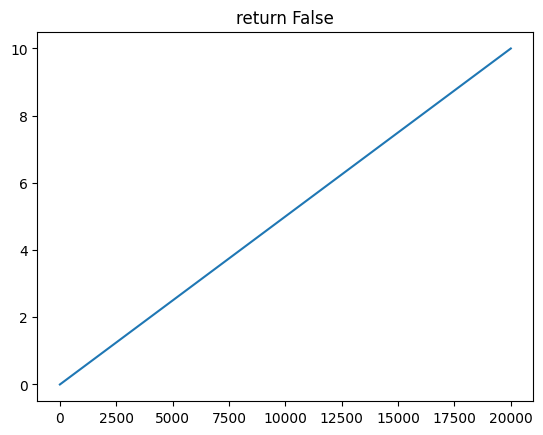

In [23]:
res = 20000

values_high = np.linspace(0, 10, res)

answer = estimate_stationarity(values_high)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values_high, label="f")
plt.title(f"return {answer}")
plt.show()


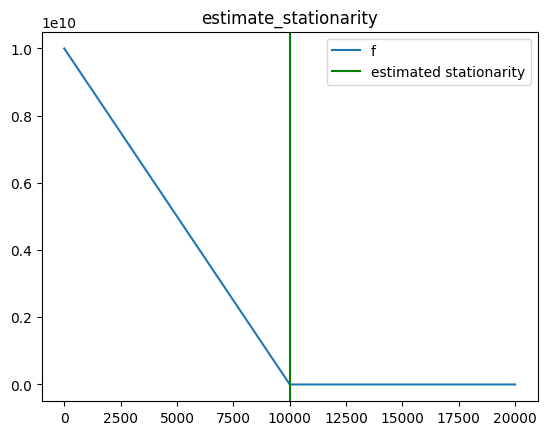

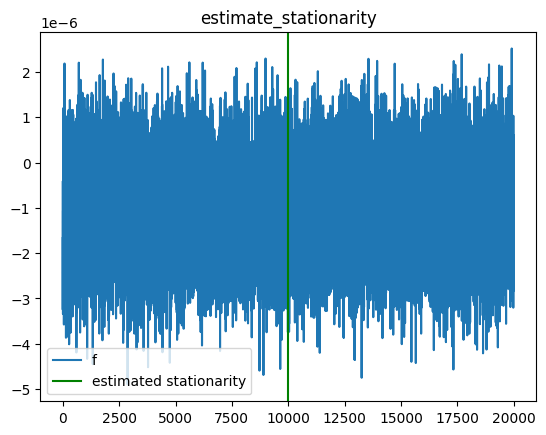

In [24]:
res = 20000
noise_amplitude = 1e-6
snr = 1e16
ramp_amplitude = noise_amplitude * snr
timesteps = np.arange(0,res)
noise = np.random.normal(-1, 1, res) * noise_amplitude

values_stationary = np.zeros(res) + noise
values_stationary[:res//2] = values_stationary[:res//2] + np.linspace(ramp_amplitude, 0, res//2)
stationary_timestep_true = estimate_stationarity(values_stationary)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values_stationary, label="f")
axs.set_title("estimate_stationarity")
axs.axvline(x=timesteps[stationary_timestep_true],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()



snr = 1e-12
ramp_amplitude = noise_amplitude * snr
values_stationary_new = np.zeros(res) + noise

values_stationary_new[:res//2] =values_stationary_new[:res//2]+  np.linspace(ramp_amplitude, 0, res//2)
stationary_timestep_false = estimate_stationarity(values_stationary_new)


f,axs = plt.subplots(1,1)
axs.plot(timesteps, values_stationary_new, label="f")
axs.set_title("estimate_stationarity")
axs.axvline(x=timesteps[stationary_timestep_true],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()


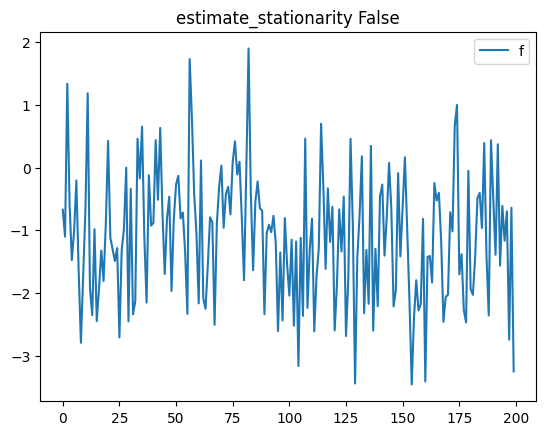

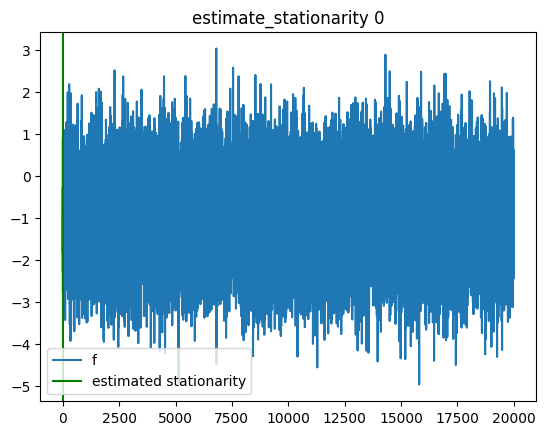

In [25]:
res = 200

values = np.random.normal(-1, 1, res)
stationary_timestep = estimate_stationarity(values)
timesteps = np.arange(0,res)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values, label="f")
axs.set_title(f"estimate_stationarity {stationary_timestep}")
axs.legend()
plt.show()


res = 20000
timesteps = np.arange(0,res)

values = np.random.normal(-1, 1, res)
stationary_timestep = estimate_stationarity(values)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values, label="f")
axs.set_title(f"estimate_stationarity {stationary_timestep}")

axs.axvline(x=timesteps[stationary_timestep],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()

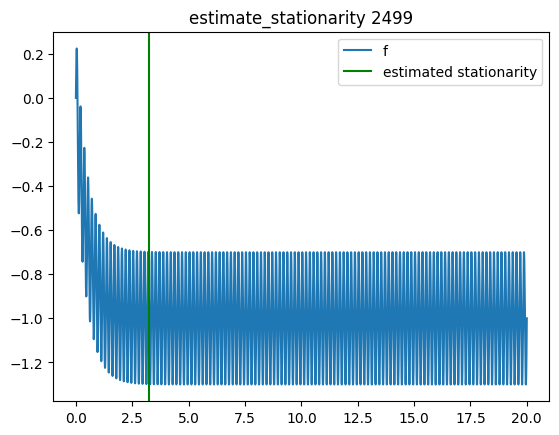

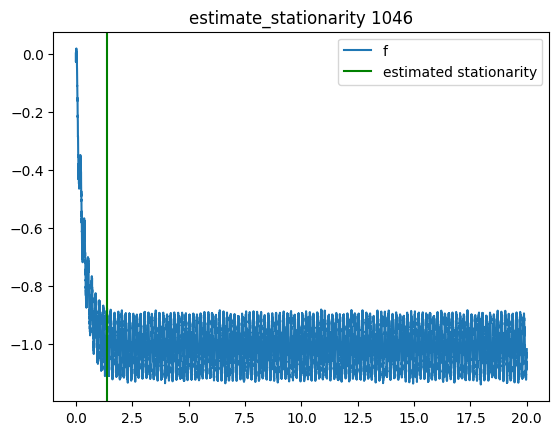

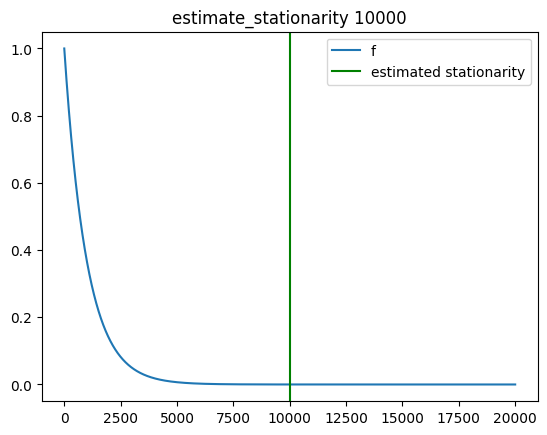

In [26]:
amplitude = 0.3
frequency = 6
time = 20
mean = -1
abate = 2

timesteps, values = signal_generator(amplitude=amplitude, frequency=frequency, mean=mean, time=time,
                                          abate=abate)
stationary_timestep = estimate_stationarity(values)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values, label="f")
axs.set_title(f"estimate_stationarity {stationary_timestep}")

axs.axvline(x=timesteps[stationary_timestep],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()


amplitude = 0.1
noiseamplitude = 0.01
frequency = 6
time = 20
mean = -1
abate = 3

timesteps, values = signal_generator(amplitude=amplitude, noise_amplitude=noiseamplitude,
                                          frequency=frequency, mean=mean, time=time,
                                          abate=abate)
stationary_timestep = estimate_stationarity(values)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values, label="f")
axs.set_title(f"estimate_stationarity {stationary_timestep}")

axs.axvline(x=timesteps[stationary_timestep],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()

res = 20000
timesteps = np.arange(0,res)
values= np.zeros(res)
noise = np.random.normal(-1, 1, res) * 1e-6
values[:res//2] = values[:res//2] + np.e ** -np.linspace(0, 10, res//2)
stationary_timestep = estimate_stationarity(values)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values, label="f")
axs.set_title(f"estimate_stationarity {stationary_timestep}")

axs.axvline(x=timesteps[stationary_timestep],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()


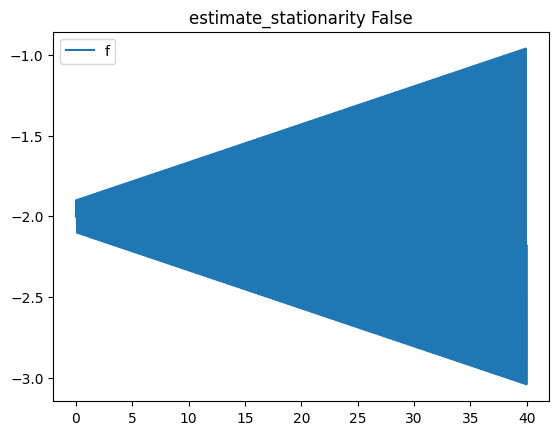

In [27]:

def signalgen_abatingsine(amplitude, frequency, mean, time):
    resolution = 36
    step = (1 / frequency) / resolution

    times = np.arange(0, time, step)

    values = (amplitude + frequency * (2 * np.pi) * times / 1600) * np.sin(frequency * (2 * np.pi) * times) + mean
    return times, values

amplitude = 0.1
frequency = 6
time = 40
mean = -2

timesteps, values = signalgen_abatingsine(amplitude=amplitude,
                                          frequency=frequency, mean=mean, time=time)

stationary_timestep = estimate_stationarity(values)

f,axs = plt.subplots(1,1)
axs.plot(timesteps, values, label="f")
axs.set_title(f"estimate_stationarity {stationary_timestep}")
axs.legend()
plt.show()

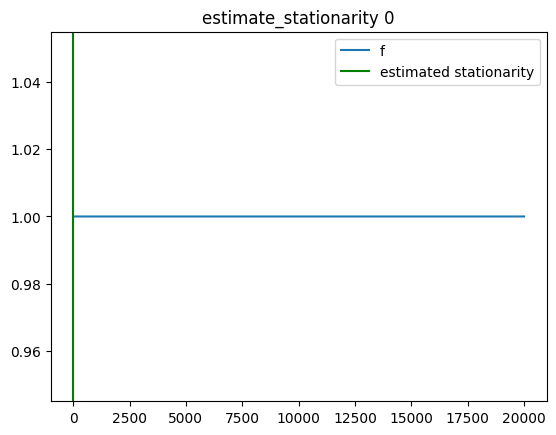

In [28]:
res = 20000
timesteps = np.arange(0,res)
values_stationary = np.ones(res)
stationary_timestep = estimate_stationarity(values_stationary)


f,axs = plt.subplots(1,1)
axs.plot(timesteps, values_stationary, label="f")
axs.set_title(f"estimate_stationarity {stationary_timestep}")
axs.axvline(x=timesteps[stationary_timestep],ymin=-1,ymax=1, color="green", label="estimated stationarity")
axs.legend()
plt.show()